# 03 · Review scores and timing sensitivity

Estimate the size of the association between late delivery and low reviews, then test what happens when responses must follow recorded delivery.

[Previous](02_delivery_and_satisfaction.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](04_findings_and_recommendations.ipynb)

In [1]:
import json
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from olist_analytics.statistics import cluster_bootstrap_difference

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/olist_analytics").is_dir(), (
    "Open from the project root or notebooks directory."
)
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"


DB = ROOT / "data/processed/olist.sqlite3"
DB_URI = DB.as_uri() + "?mode=ro"

## How large is the low-score gap?

Read the relevant order-level columns once. Keep eligible deliveries with an observed chosen review. Score 1 or 2 counts as low. The table reports both the low-score count and the reviewed denominator.

,reviewed_orders,low_scores,low_score_rate
is_late,,,
On time,89443,8289,0.092674
Late,6381,3983,0.624197


Late minus on time 53.15 percentage points


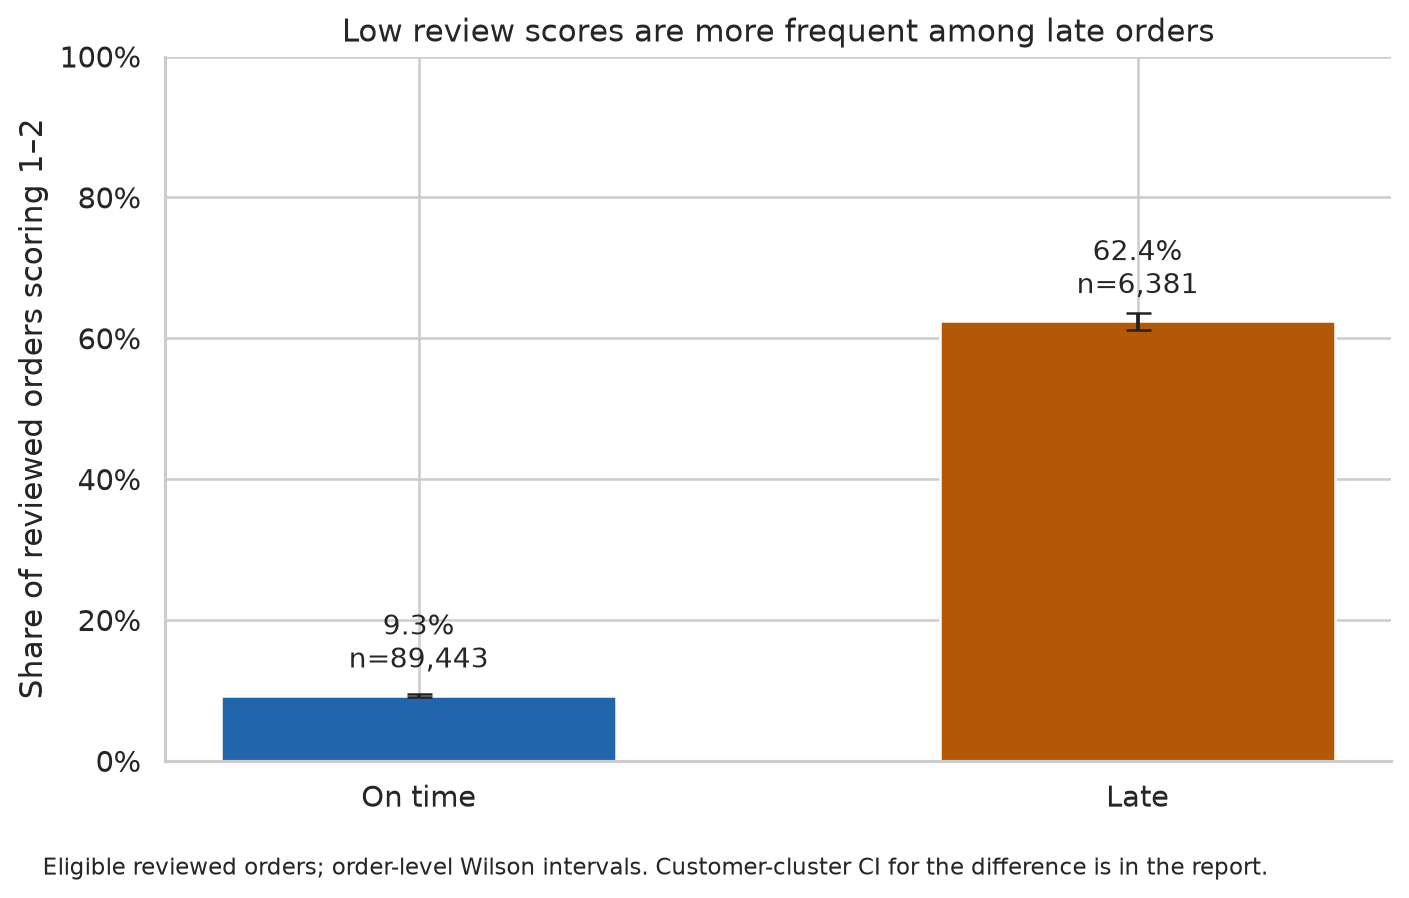

In [2]:
with closing(sqlite3.connect(DB_URI, uri=True)) as connection:
    reviewed = pd.read_sql_query(
        """
        SELECT customer_unique_id, delivery_eligible, is_late, review_score,
               review_answered_after_delivery
        FROM order_fact
        WHERE delivery_eligible = 1 AND review_score IS NOT NULL
    """,
        connection,
    )

reviewed["low_score"] = reviewed["review_score"].le(2)
rates = reviewed.groupby("is_late")["low_score"].agg(
    reviewed_orders="size", low_scores="sum", low_score_rate="mean"
)
display(rates.rename(index={0: "On time", 1: "Late"}))
gap = rates.at[1, "low_score_rate"] - rates.at[0, "low_score_rate"]
print(f"Late minus on time {gap * 100:.2f} percentage points")
display(Image(filename=str(REPORTS / "figures/03_low_review_rates.png"), width=900))

Low scores occur in 62.42% of late reviewed orders and 9.27% of on-time reviewed orders. The chart’s descriptive intervals compare rates. For the gap, resample customers to account for repeat orders within customers.

## How uncertain is the gap, and what do the ordinal scores show?

Use 2,000 seeded cluster resamples. Each draw keeps a customer’s orders together. The exploratory ordinal diagnostics use the earliest eligible reviewed order per customer. The percentile interval approximates sampling variability under this approach and leaves confounding and response selection unresolved.

Customer-cluster 95% interval 51.88 to 54.36 points


cramers_v                          0.397906
cliffs_delta_late_minus_on_time   -0.638940
dtype: float64

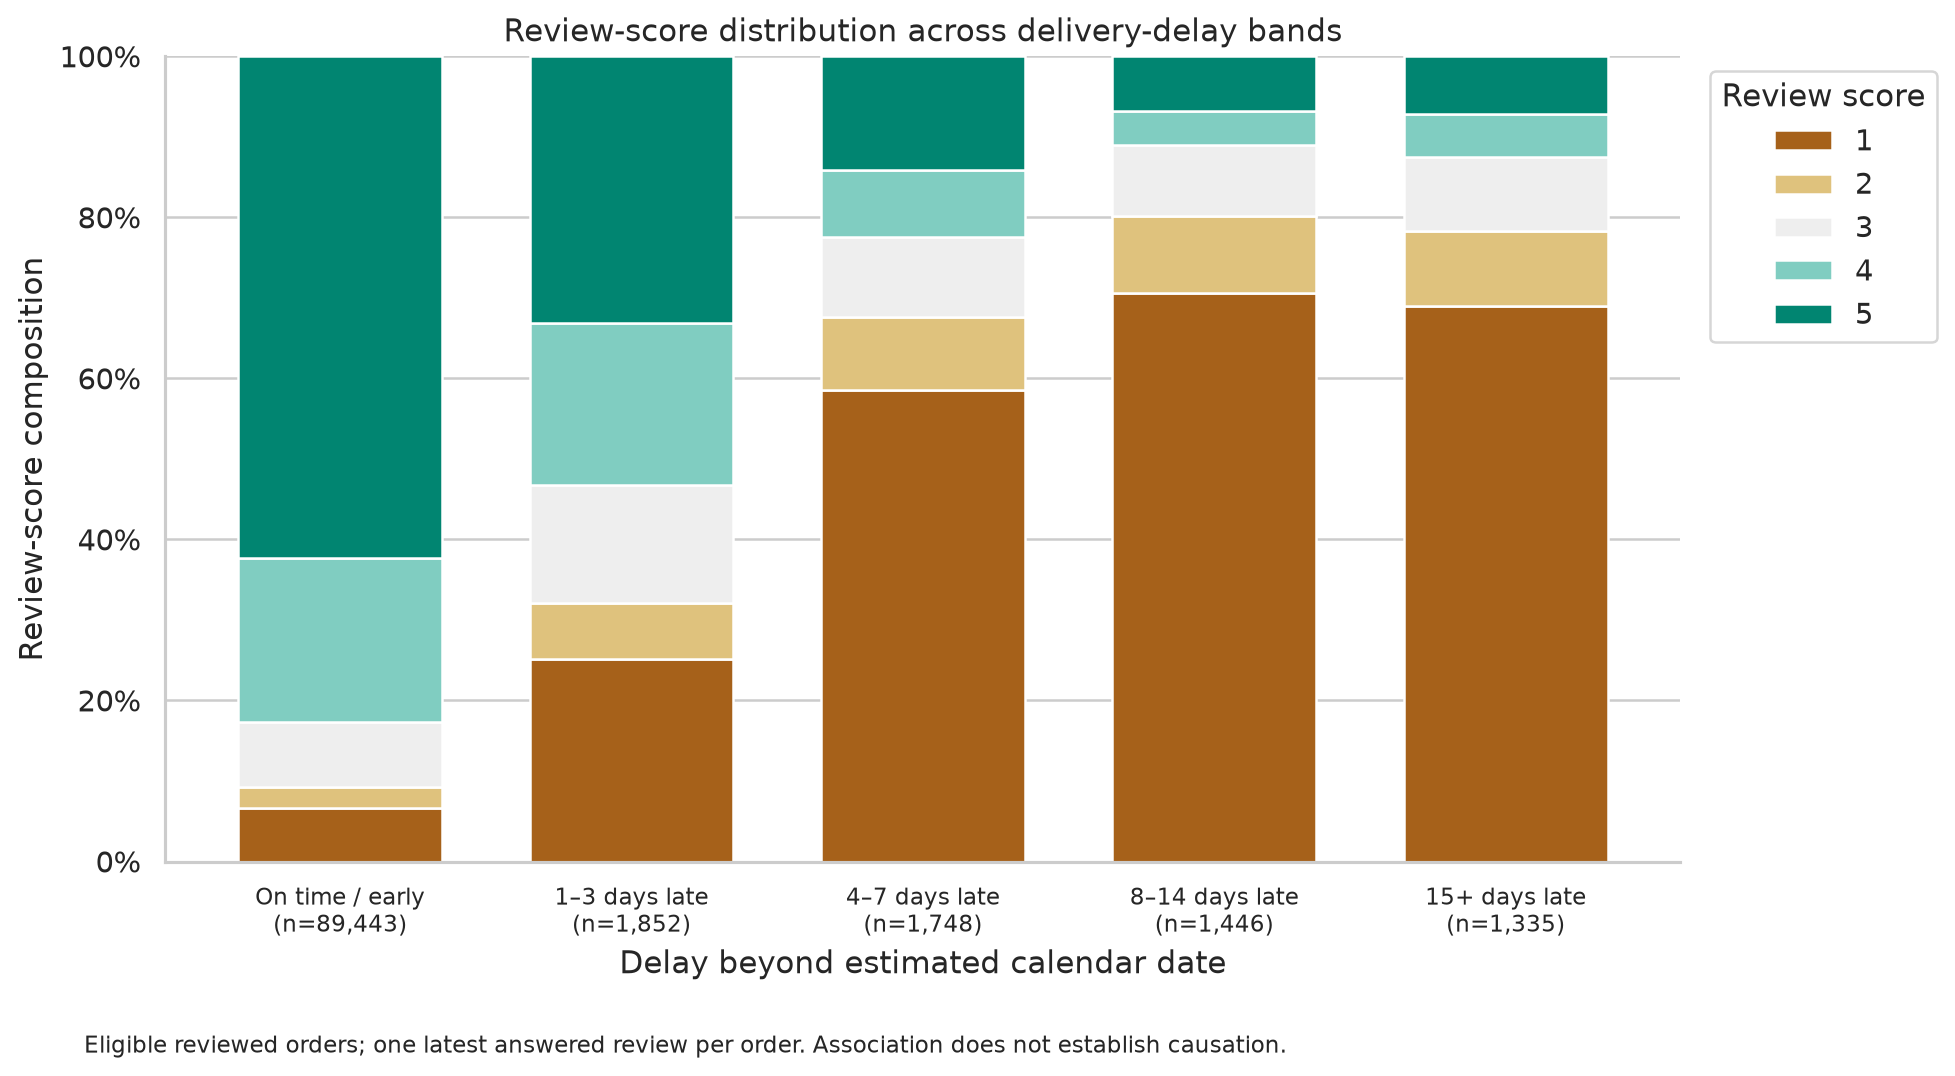

In [3]:
stats = json.loads((REPORTS / "statistics.json").read_text())
interval = cluster_bootstrap_difference(reviewed)
assert np.isclose(gap, stats["primary"]["risk_difference"])
np.testing.assert_allclose(
    [interval["lower"], interval["upper"]],
    [stats["risk_difference_ci"]["lower"], stats["risk_difference_ci"]["upper"]],
)
lower, upper = interval["lower"] * 100, interval["upper"] * 100
print(f"Customer-cluster 95% interval {lower:.2f} to {upper:.2f} points")
diagnostics = stats["independent_customer_diagnostics"]
display(
    pd.Series(
        {
            key: diagnostics[key]
            for key in ("cramers_v", "cliffs_delta_late_minus_on_time")
        }
    )
)
display(Image(filename=str(REPORTS / "figures/04_review_distribution.png"), width=900))

The interval spans 51.88 to 54.36 percentage points. The ordinal distribution also shifts toward low scores in the late group. Order mix, seller, carrier and survey timing can all affect the observed association.

## Does the gap persist when reviews follow delivery?

Use on-or-after delivery timestamps to form a separate cohort. Recompute its gap and compare it with the saved timing and definition sensitivity scenarios.

On or after delivery, 91,171 reviewed orders


,scenario,reviewed_orders,gap_pp
0,Primary: latest answered review; calendar-day ...,95824,53.152329
1,Review answered on/after actual delivery,91171,10.193131
2,Exclude carrier chronology anomalies,95637,53.162783
3,Earliest eligible reviewed order per customer,92747,53.268628
4,Alternative: strict timestamp deadline,95824,44.844493
5,Earliest answered review instead of latest,95824,53.096351


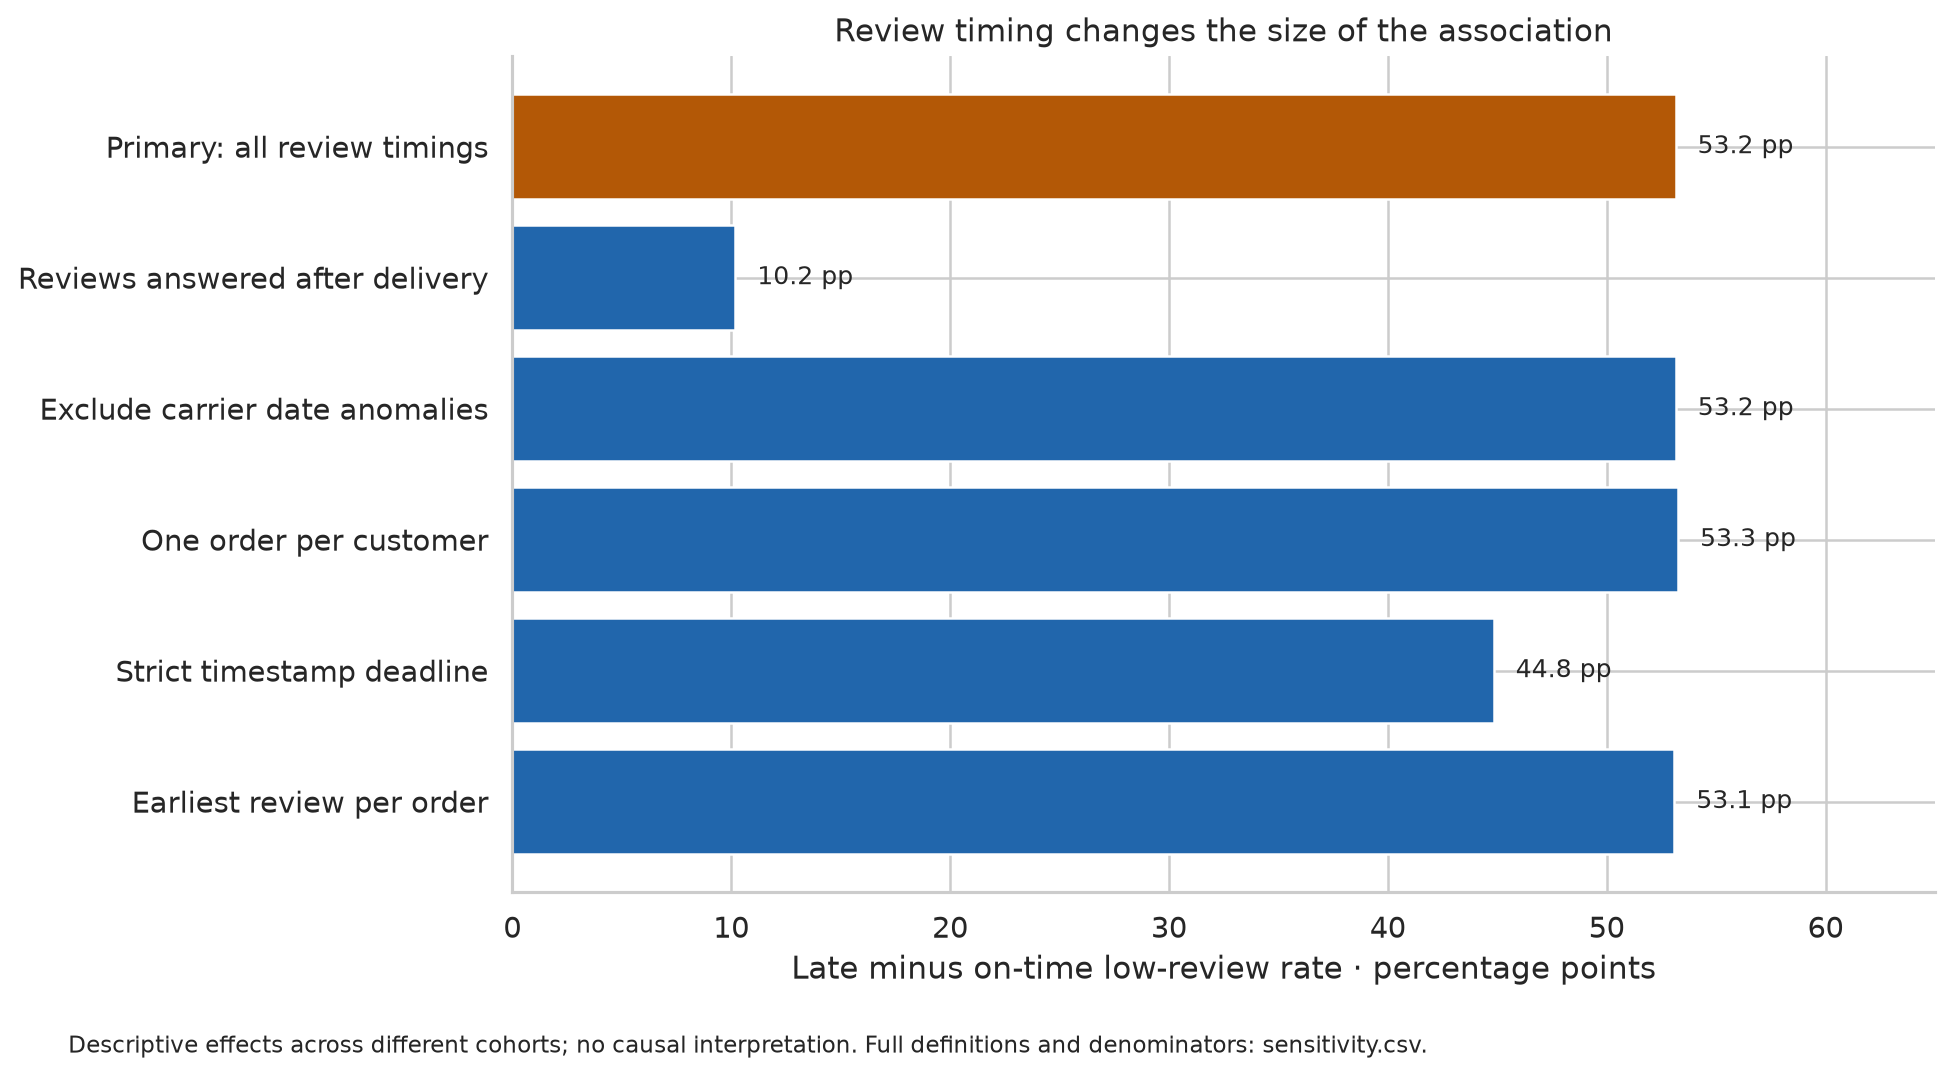

In [4]:
after_delivery = reviewed.loc[reviewed["review_answered_after_delivery"].eq(1)]
rates_after = after_delivery.groupby("is_late")["low_score"].mean()
gap_after = rates_after.loc[1] - rates_after.loc[0]
sensitivity = pd.read_csv(TABLES / "sensitivity.csv")
timing = sensitivity.loc[
    sensitivity["scenario"].eq("Review answered on/after actual delivery")
].iloc[0]
assert len(after_delivery) == timing["reviewed_orders"]
assert np.isclose(gap_after, timing["risk_difference"])
print(f"On or after delivery, {len(after_delivery):,} reviewed orders")
display(
    sensitivity[["scenario", "reviewed_orders", "risk_difference"]]
    .assign(risk_difference=lambda frame: frame["risk_difference"].mul(100))
    .rename(columns={"risk_difference": "gap_pp"})
)
display(Image(filename=str(REPORTS / "figures/06_sensitivity.png"), width=900))

The gap drops from 53.15 to 10.19 percentage points. The restricted cohort excludes feedback submitted while customers were still waiting and changes the composition of the groups. These historical comparisons motivate a follow-up test of communication and delivery interventions.

[Previous](02_delivery_and_satisfaction.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](04_findings_and_recommendations.ipynb)